# Smart Healthcare Data Analytics and Prediction Platform
**Big Data – Mid-Term Minor Project**  
Name: `<your name>`   Roll no.: `<roll number>`   Programme: B.Tech CSE

This notebook builds the data foundation of a hospital analytics platform using PySpark: it brings in data from three hospital systems, stores it untouched (Bronze), cleans and validates it (Silver), and then runs Spark processing to produce KPIs and a prediction-ready table. All data is simulated (fixed random seed) – no real patient records are used.

The same code is also organised as a modular project (`src/`, `run_pipeline.py`, tests, Airflow DAG) in the accompanying GitHub repository.

## 1. Problem definition

**Domain:** healthcare – hospital information systems.

**Problem.** A hospital group keeps patient registration, admission records and bedside vital signs in three separate systems. The data is full of inconsistencies (mixed date formats, bills written as `₹12,500` or `12500 INR`, temperatures in °C and °F, duplicate and orphan records, sensor glitches), so reports built on it can't be trusted. As a result, administrators can't measure cost and stay length reliably, and patients who keep coming back within 30 days (readmissions) are not identified.

**Objectives**
- bring data from a CSV file, a database and a REST API into one place;
- keep an untouched, traceable copy of everything received;
- produce a clean, validated dataset and keep rejected records for review instead of discarding them;
- use PySpark to compute department KPIs, trends, vitals alerts and a 30-day readmission label.

**Users:** hospital administrators (cost, capacity), doctors (patient deterioration), quality team (readmissions).

**Expected outcome:** trusted Silver tables plus analysis-ready outputs; the readmission label prepares the ground for a prediction model later.

`Sources (CSV · DB · API)  →  Bronze (raw)  →  Silver (clean) + Quarantine  →  PySpark processing (features, KPIs)`

### Setup
Starts a local Spark session and creates an empty `healthcare_pipeline/` folder (it is wiped on every run, so results are reproducible). `ansi.enabled=false` makes unparseable text become `NULL` instead of crashing – we handle those nulls ourselves in Silver.

In [1]:
import json, random, sqlite3, shutil, warnings
from pathlib import Path
from datetime import datetime, timedelta, timezone

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from pyspark.sql import SparkSession, functions as F, Window
from pyspark.sql.types import StructType, StructField, StringType, ArrayType

warnings.filterwarnings("ignore", category=FutureWarning)   # cosmetic: PySpark/pandas version notice
random.seed(42)
np.random.seed(42)

BASE = Path("healthcare_pipeline")
RAW, BRONZE, SILVER, PROCESSED, QUARANTINE = (BASE / d for d in ["raw", "bronze", "silver", "processed", "quarantine"])
if BASE.exists():
    shutil.rmtree(BASE)                      # fresh run every time -> fully reproducible
for p in (RAW, BRONZE, SILVER, PROCESSED, QUARANTINE, RAW / "vitals_api"):
    p.mkdir(parents=True)

spark = (SparkSession.builder
         .appName("SmartHealthcarePlatform")
         .master("local[*]")
         .config("spark.sql.shuffle.partitions", "8")
         .config("spark.sql.session.timeZone", "Asia/Kolkata")
         .config("spark.sql.ansi.enabled", "false")
         .config("spark.ui.showConsoleProgress", "false")
         .getOrCreate())
spark.sparkContext.setLogLevel("ERROR")
print("Spark version :", spark.version)
print("Master        :", spark.sparkContext.master)
print("Workspace     :", BASE, "(raw / bronze / silver / quarantine / processed)")

Spark version : 4.2.0
Master        : local[*]
Workspace     : healthcare_pipeline (raw / bronze / silver / quarantine / processed)


## 2. Data sources and ingestion

| Source | Kind | What it holds |
|---|---|---|
| `patients_registry.csv` | CSV file | demographics, blood group, insurance, chronic-condition flags |
| `hospital_his.db` (table `admissions`) | database (SQLite stand-in) | department, diagnosis, severity, dates, bill, outcome |
| vitals API | paginated JSON (mocked locally) | heart rate, BP, temperature, SpO₂, glucose, respiration |

Since real hospital data cannot be shared, the three sources are generated in code. Realistic problems are injected on purpose so the cleaning step has something to do: duplicate rows, missing values, numbers stored as text (`"78 bpm"`, `"97%"`), inconsistent spellings (`M/male/MALE`, `cardio/Cardiology`, `ER/Emergency`), mixed date formats and units, impossible values (discharge before admission, SpO₂ = 127), and records pointing to patients or admissions that do not exist.

In [2]:
# ───────── Source 1: patient registry (CSV) ─────────
REF_DATE = datetime(2026, 9, 30)            # snapshot date of the extract
START    = datetime(2024, 10, 1)            # two years of history
N_PATIENTS = 1500

CITIES = ["Delhi", "Mumbai", "Bengaluru", "Chennai", "Kolkata", "Hyderabad", "Pune", "Jaipur", "Lucknow", "Chandigarh"]
BLOOD  = ["A+", "A-", "B+", "B-", "O+", "O-", "AB+", "AB-"]
INSUR  = ["Government", "Private", "Corporate", "Uninsured"]
BOOL_STYLES = [("Y", "N"), ("Yes", "No"), ("1", "0"), ("True", "False"), ("y", "n")]
G_VARIANTS = {"Male": ["Male", "male", "M", "MALE", "m"], "Female": ["Female", "female", "F", "FEMALE", "f"]}

def messy_case(s, p_upper=0.07, p_lower=0.05, p_pad=0.04):
    r = random.random()
    if r < p_upper:                 return s.upper()
    if r < p_upper + p_lower:       return s.lower()
    if r < p_upper + p_lower + p_pad: return f"  {s}  "
    return s

def enc_bool(v):
    if random.random() < 0.03: return None
    yes, no = random.choice(BOOL_STYLES)
    return yes if v else no

patients, truth = [], {}
for i in range(1, N_PATIENTS + 1):
    pid  = f"P{i:05d}"
    age  = int(np.clip(np.random.gamma(4.5, 10), 1, 92))
    dob  = REF_DATE - timedelta(days=age * 365 + random.randint(0, 364))
    dia  = random.random() < 0.03 + age / 300
    htn  = random.random() < 0.05 + age / 200
    gender = random.choices(["Male", "Female", "Other"], [0.49, 0.49, 0.02])[0]
    truth[pid] = dict(age=age, dia=dia, htn=htn)            # hidden "ground truth" used to make later data realistic

    r = random.random()
    if   r < 0.03: dob_s = None
    elif r < 0.04: dob_s = (REF_DATE + timedelta(days=random.randint(30, 900))).strftime("%Y-%m-%d")   # DOB in the future
    elif r < 0.05: dob_s = "1890-01-01"                                                              # impossible age
    elif r < 0.11: dob_s = dob.strftime("%d/%m/%Y")                                                  # other date format
    else:          dob_s = dob.strftime("%Y-%m-%d")

    g_s  = None if random.random() < 0.04 else (random.choice(G_VARIANTS[gender]) if gender in G_VARIANTS else random.choice(["Other", "other"]))
    city = None if random.random() < 0.06 else messy_case(random.choice(CITIES))
    bg   = random.choices(BLOOD, [.30, .06, .25, .04, .25, .04, .04, .02])[0]
    r    = random.random()
    bg   = None if r < .05 else bg.lower() if r < .08 else "Unknown" if r < .10 else bg
    ins  = None if random.random() < 0.05 else messy_case(random.choices(INSUR, [.35, .30, .20, .15])[0], .10, .05, .03)
    reg  = (START - timedelta(days=random.randint(0, 1500))).strftime("%Y-%m-%d")
    upd  = REF_DATE - timedelta(days=random.randint(0, 365), hours=random.randint(0, 23))
    patients.append(dict(patient_id=pid, gender=g_s, dob=dob_s, city=city, blood_group=bg, insurance_type=ins,
                         has_diabetes=enc_bool(dia), has_hypertension=enc_bool(htn),
                         registration_date=reg, last_updated=upd.strftime("%Y-%m-%d %H:%M:%S")))

# registry re-sync glitch: ~4% of patients appear twice; the newer copy has a different city
dups = []
for rec in random.sample(patients, int(0.04 * len(patients))):
    d = dict(rec)
    d["city"] = random.choice(CITIES)
    d["last_updated"] = (datetime.strptime(rec["last_updated"], "%Y-%m-%d %H:%M:%S") + timedelta(days=random.randint(1, 60))).strftime("%Y-%m-%d %H:%M:%S")
    dups.append(d)
for _ in range(6):                                           # a few rows with no patient_id at all
    d = dict(random.choice(patients)); d["patient_id"] = None; dups.append(d)

patients_df = pd.DataFrame(patients + dups).sample(frac=1, random_state=1).reset_index(drop=True)
patients_df.to_csv(RAW / "patients_registry.csv", index=False)
print(f"patients_registry.csv : {len(patients_df):,} rows  ({len(dups)} duplicate / key-less rows injected)")
patients_df.head(8)

patients_registry.csv : 1,566 rows  (66 duplicate / key-less rows injected)


,patient_id,gender,dob,city,blood_group,insurance_type,has_diabetes,has_hypertension,registration_date,last_updated
0,P00061,M,2008-01-24,Delhi,b+,Private,N,No,2021-02-28,2026-02-28 15:00:00
1,P00996,Male,13/02/1974,NaN,AB+,Private,0,1,2023-01-23,2026-07-17 20:00:00
2,P01469,Female,1963-11-22,Jaipur,AB+,Private,False,NaN,2023-08-07,2026-08-30 11:00:00
3,P00896,male,2026-11-13,Hyderabad,AB+,Uninsured,False,False,2021-03-17,2026-06-28 02:00:00
4,P00322,NaN,1977-06-06,Bengaluru,A+,Private,N,0,2021-10-06,2025-11-19 11:00:00
5,P00987,female,1962-09-21,Mumbai,O+,Uninsured,y,0,2024-04-10,2026-04-20 22:00:00
6,P01437,F,1934-02-05,Bengaluru,A+,Government,1,Yes,2021-07-07,2025-12-18 11:00:00
7,P01431,Male,2005-10-22,Pune,O+,NaN,N,1,2022-02-17,2025-11-01 21:00:00


In [3]:
# ───────── Source 2: hospital admissions (relational database) ─────────
DEPTS = {   # dept: (diagnoses, typical length of stay, cost per day in INR)
    "Cardiology":       (["Heart Failure", "Myocardial Infarction", "Hypertensive Crisis", "Arrhythmia"], 5, 14000),
    "Endocrinology":    (["Diabetic Ketoacidosis", "Type 2 Diabetes", "Thyroid Disorder"], 4, 9000),
    "Pulmonology":      (["COPD Exacerbation", "Pneumonia", "Asthma"], 5, 11000),
    "Orthopedics":      (["Fracture", "Joint Replacement", "Spinal Injury"], 6, 16000),
    "Neurology":        (["Stroke", "Epilepsy", "Migraine"], 6, 15000),
    "General Medicine": (["Viral Fever", "Dengue", "Typhoid", "Gastroenteritis"], 3, 6000),
    "Nephrology":       (["Chronic Kidney Disease", "Kidney Stones"], 5, 12000),
}
DEPT_W = [.16, .12, .13, .14, .12, .25, .08]
pids = list(truth)
p_weights = [1 + 2 * t["dia"] + 2 * t["htn"] + t["age"] / 40 for t in truth.values()]   # chronic / older patients are admitted more often

def make_adm(pid, admit, dept=None, atype=None):
    dept = dept or random.choices(list(DEPTS), DEPT_W)[0]
    diags, base_los, cpd = DEPTS[dept]
    sev   = random.choices([1, 2, 3, 4, 5], [.15, .30, .30, .18, .07])[0]
    atype = atype or random.choices(["Emergency", "Elective", "Urgent"], [.45, .35, .20])[0]
    los   = max(1, int(round(base_los * (0.6 + 0.25 * sev) * np.random.lognormal(0, 0.35))))
    disch = admit + timedelta(days=los, hours=random.randint(-3, 5))
    bill  = cpd * los * (0.8 + 0.15 * sev) * np.random.lognormal(0, 0.25) * (1.15 if atype == "Emergency" else 1)
    r = random.random(); pd_ = 0.0015 * sev ** 2
    outcome = "Deceased" if r < pd_ else "Transferred" if r < pd_ + 0.03 else "Discharged"
    return dict(patient_id=pid, department=dept, doctor_id=f"D{list(DEPTS).index(dept) * 10 + random.randint(1, 9):03d}",
                admission_type=atype, primary_diagnosis=random.choice(diags), severity=sev,
                admit=admit, discharge=disch, los=los, bill=int(round(bill)), outcome=outcome)

base = []
for _ in range(5200):
    admit = START + timedelta(days=random.randint(0, 715), hours=random.randint(0, 23), minutes=random.randint(0, 59))
    base.append(make_adm(random.choices(pids, p_weights)[0], admit))

follow_ups = []                       # ~14% of admissions are followed by a re-admission within 2-28 days
for a in base:
    if a["outcome"] != "Deceased" and random.random() < 0.14:
        nxt = a["discharge"] + timedelta(days=random.randint(2, 28), hours=random.randint(0, 23))
        if nxt < REF_DATE - timedelta(days=10):
            follow_ups.append(make_adm(a["patient_id"], nxt, dept=a["department"] if random.random() < .7 else None, atype="Emergency"))

adm_true = sorted(base + follow_ups, key=lambda a: a["admit"])
for n, a in enumerate(adm_true, 1):
    a["admission_id"] = f"A{n:06d}"

# ---- turn the clean "truth" into messy database rows ----
ABBR = {"Cardiology": "Cardio", "Orthopedics": "Ortho", "General Medicine": "Gen Med", "Neurology": "Neuro"}
SEV_WORDS = {1: "low", 2: "mild", 3: "moderate", 4: "high", 5: "critical"}

def fmt_dt(dt):
    return dt.strftime("%d/%m/%Y %H:%M") if random.random() < 0.10 else dt.strftime("%Y-%m-%d %H:%M:%S")

def fmt_bill(b):
    r = random.random()
    if r < .04: return None
    if r < .06: return str(-abs(b))                 # invalid negative bill
    if r < .18: return f"₹{b:,}"
    if r < .26: return f"{b} INR"
    if r < .30: return f"Rs. {b:,}"
    return str(b)

def messy_dept(d):
    r = random.random()
    if r < .05: return d.upper()
    if r < .08: return d.lower()
    if r < .11: return f"  {d} "
    if r < .13 and d in ABBR: return ABBR[d]
    return d

def messy_type(t):
    r = random.random()
    return t.lower() if r < .06 else t.upper() if r < .10 else "ER" if (t == "Emergency" and r < .13) else t

def messy_outcome(o):
    r = random.random()
    return o.lower() if r < .05 else o.upper() if r < .08 else "Recovered" if (o == "Discharged" and r < .12) else o

rows = []
for a in adm_true:
    r = random.random()
    pid = a["patient_id"] if r > .015 else (f"P{random.randint(9000, 9999):05d}" if r > .005 else None)   # orphan / null patient
    admit_s = None if random.random() < .005 else fmt_dt(a["admit"])
    r = random.random()
    if   r < .015: disch_s = fmt_dt(a["admit"] - timedelta(days=random.randint(1, 3)))   # discharge BEFORE admission
    elif r < .035: disch_s = None
    else:          disch_s = fmt_dt(a["discharge"])
    r = random.random()
    sev_s = None if r < .04 else SEV_WORDS[a["severity"]] if r < .16 else str(a["severity"])
    rows.append((a["admission_id"], pid, messy_dept(a["department"]), None if random.random() < .03 else a["doctor_id"],
                 messy_type(a["admission_type"]), None if random.random() < .02 else a["primary_diagnosis"], sev_s,
                 admit_s, disch_s, fmt_bill(a["bill"]), messy_outcome(a["outcome"])))
rows += random.sample(rows, int(0.025 * len(rows)))          # duplicated rows (double-submitted records)
random.shuffle(rows)

db_path = RAW / "hospital_his.db"
con = sqlite3.connect(db_path)
con.execute("DROP TABLE IF EXISTS admissions")
con.execute("""CREATE TABLE admissions (admission_id TEXT, patient_id TEXT, department TEXT, doctor_id TEXT,
               admission_type TEXT, primary_diagnosis TEXT, severity TEXT, admit_date TEXT, discharge_date TEXT,
               total_bill TEXT, outcome TEXT)""")
con.executemany("INSERT INTO admissions VALUES (?,?,?,?,?,?,?,?,?,?,?)", rows)
con.commit()
print("hospital_his.db  ->  admissions :", con.execute("SELECT COUNT(*) FROM admissions").fetchone()[0], "rows")
pd.read_sql("SELECT * FROM admissions LIMIT 8", con)

hospital_his.db  ->  admissions : 6083 rows


,admission_id,patient_id,department,doctor_id,admission_type,primary_diagnosis,severity,admit_date,discharge_date,total_bill,outcome
0,A001443,P00413,Cardio,D009,Emergency,Heart Failure,5,2025-03-23 10:25:00,2025-04-02 14:25:00,199158,Discharged
1,A002106,P01370,Nephrology,D063,Emergency,Kidney Stones,NaN,2025-06-10 13:16:00,2025-06-14 18:16:00,72613 INR,Discharged
2,A001179,P00601,General Medicine,D056,Emergency,Typhoid,moderate,2025-02-19 05:26:00,2025-02-25 02:26:00,69540,Discharged
3,A000500,P00448,Pulmonology,D021,Emergency,Asthma,1,2024-12-01 22:26:00,2024-12-06 03:26:00,43742,Discharged
4,A003224,P00947,Pulmonology,D024,Emergency,Pneumonia,3,2025-10-26 10:23:00,2025-11-01 10:23:00,109985,Discharged
5,A005074,P00256,Cardiology,D002,Emergency,Myocardial Infarction,NaN,2026-06-07 23:17:00,2026-06-12 04:17:00,"Rs. 92,401",Discharged
6,A000295,P00454,General Medicine,D055,elective,Dengue,mild,07/11/2024 03:08,2024-11-12 05:08:00,33108,Discharged
7,A003504,P00040,General Medicine,D052,Elective,NaN,3,2025-11-29 05:16:00,2025-12-04 06:16:00,31400,Discharged


In [4]:
# ───────── Source 3: bedside vitals (paginated REST API, mocked locally) ─────────
ri = lambda v: int(round(float(v)))
rf = lambda v, n=1: round(float(v), n)
IST = timezone(timedelta(hours=5, minutes=30))

def vitals_truth(adm, k, n):
    s = (adm["severity"] - 1) / 4 * (1 - 0.6 * k / max(n - 1, 1))      # sicker patients -> worse vitals, improving over the stay
    diabetic = truth[adm["patient_id"]]["dia"]
    return dict(hr=np.random.normal(74 + 28 * s, 7), sys=np.random.normal(120 + 22 * s, 10), dia=np.random.normal(79 + 8 * s, 6),
                temp=np.random.normal(36.8 + 1.3 * s, 0.25), spo2=np.clip(np.random.normal(97.5 - 7 * s, 1.2), 70, 100),
                glu=np.random.normal((150 if diabetic else 100) + 35 * s, 18), resp=np.random.normal(16 + 6 * s, 2))

DEVICES = ["Bedside Monitor", "Wearable", "Manual Entry"]
readings = []
for adm in adm_true:
    n = int(np.clip(adm["los"] + 1, 2, 6))
    span = (adm["discharge"] - adm["admit"]) / n
    for k in range(n):
        t = vitals_truth(adm, k, n)
        ts = adm["admit"] + span * k + timedelta(minutes=random.randint(0, 90))
        r = random.random()
        recorded = None if r < .01 else int(ts.replace(tzinfo=IST).timestamp()) if r < .07 else ts.strftime("%Y-%m-%dT%H:%M:%S")

        r = random.random(); hr = None if r < .03 else random.choice([0, 300]) if r < .045 else f"{ri(t['hr'])} bpm" if r < .095 else ri(t["hr"])
        sys_, dia_ = ri(t["sys"]), ri(t["dia"])
        if random.random() < .01: sys_, dia_ = dia_, sys_                                  # swapped BP fields
        sys_ = None if random.random() < .03 else sys_
        dia_ = None if random.random() < .03 else dia_
        unit = "F" if random.random() < .15 else "C"
        temp = rf(t["temp"] * 9 / 5 + 32) if unit == "F" else rf(t["temp"])
        r = random.random(); temp = None if r < .03 else (rf(temp * 10) if r < .04 else temp)   # decimal-slip error
        r = random.random(); spo2 = None if r < .03 else random.choice([0, 101, 127]) if r < .045 else f"{ri(t['spo2'])}%" if r < .095 else ri(t["spo2"])
        r = random.random(); glu = None if r < .06 else "N/A" if r < .08 else ri(t["glu"])
        resp = None if random.random() < .04 else ri(t["resp"])
        r = random.random()
        pid = None if r < .01 else adm["patient_id"]
        aid = "A999999" if random.random() < .01 else adm["admission_id"]                  # reading for an unknown admission
        dev = random.choice(DEVICES); dev = dev.upper() if random.random() < .05 else dev
        readings.append(dict(patient_id=pid, admission_id=aid, recorded_at=recorded, heart_rate=hr, systolic_bp=sys_, diastolic_bp=dia_,
                             temperature=temp, temp_unit=unit, spo2=spo2, blood_glucose=glu, respiration_rate=resp, source_device=dev))

readings += random.sample(readings, int(0.03 * len(readings)))                              # API replays some records
random.shuffle(readings)
for i, rd in enumerate(readings, 1):
    rd["reading_id"] = f"R{i:07d}"
# replayed rows are the same record objects, so they carry the SAME reading_id -> true duplicates

PAGE_SIZE = 3000
def mock_vitals_api(page, page_size=PAGE_SIZE):
    """Stand-in for GET /api/v1/vitals?page=N  (same JSON envelope a real API would return)."""
    total_pages = -(-len(readings) // page_size)
    return {"status": "ok", "page": page, "total_pages": total_pages, "data": readings[(page - 1) * page_size: page * page_size]}

# ---- the ingestion client: walk through every page and land the raw responses on disk ----
page = 1
while True:
    resp = mock_vitals_api(page)
    (RAW / "vitals_api" / f"vitals_page_{page:03d}.json").write_text(json.dumps(resp))
    if page >= resp["total_pages"]:
        break
    page += 1
print(f"Vitals API: fetched {resp['total_pages']} pages, {len(readings):,} readings")
print(json.dumps(mock_vitals_api(1)["data"][0], indent=1))

Vitals API: fetched 12 pages, 33,229 readings
{
 "patient_id": "P00378",
 "admission_id": "A001003",
 "recorded_at": "2025-01-28T22:33:00",
 "heart_rate": 81,
 "systolic_bp": 108,
 "diastolic_bp": 70,
 "temperature": 36.7,
 "temp_unit": "C",
 "spo2": 98,
 "blood_glucose": 94,
 "respiration_rate": 16,
 "source_device": "Manual Entry",
 "reading_id": "R0000001"
}


In [5]:
SOURCE_ROWS = {
    "patients": len(patients_df),
    "admissions": con.execute("SELECT COUNT(*) FROM admissions").fetchone()[0],
    "vitals": len(readings),
}
inventory = pd.DataFrame([
    ("patients_registry.csv",     "CSV file",        SOURCE_ROWS["patients"]),
    ("hospital_his.db/admissions", "Database table",  SOURCE_ROWS["admissions"]),
    (f"vitals API ({resp['total_pages']} pages)", "REST API / JSON", SOURCE_ROWS["vitals"]),
], columns=["source", "type", "rows"])
print("Source inventory (rows as delivered, before any cleaning):\n")
print(inventory.to_string(index=False))

Source inventory (rows as delivered, before any cleaning):

                    source            type  rows
     patients_registry.csv        CSV file  1566
hospital_his.db/admissions  Database table  6083
     vitals API (12 pages) REST API / JSON 33229


## 3. Bronze layer
Bronze holds the data exactly as received – every column as text, duplicates and errors included – written as Parquet. Each row also gets lineage columns: `_source_system`, `_source_file`, `_ingested_at`, `_batch_id`, `_row_hash` (and `_ingest_date` as the partition). The check below confirms no row was lost on the way in.

In [6]:
BATCH_ID = "batch_" + datetime.now().strftime("%Y%m%d_%H%M%S")

def add_lineage(df, source_system):
    """Attach ingestion metadata; _source_file must already exist on df."""
    data_cols = [c for c in df.columns if not c.startswith("_")]
    return (df.withColumn("_source_system", F.lit(source_system))
              .withColumn("_ingested_at", F.current_timestamp())
              .withColumn("_batch_id", F.lit(BATCH_ID))
              .withColumn("_ingest_date", F.current_date())
              .withColumn("_row_hash", F.sha2(F.concat_ws("||", *[F.coalesce(F.col(c), F.lit("<null>")) for c in data_cols]), 256)))

def write_bronze(df, name):
    df.write.mode("overwrite").partitionBy("_ingest_date").parquet(str(BRONZE / name))

basename = lambda: F.element_at(F.split(F.col("_metadata.file_path"), "/"), -1)

# 1) CSV source ------------------------------------------------------------
patients_raw = (spark.read.option("header", True).option("inferSchema", False)
                .csv(str(RAW / "patients_registry.csv"))
                .withColumn("_source_file", basename()))
write_bronze(add_lineage(patients_raw, "registration_desk_csv"), "patients")

# 2) Database source (SQLite here; on a real cluster this is spark.read.jdbc(...)) ---------
cur = con.execute("SELECT * FROM admissions")
adm_cols = [c[0] for c in cur.description]
adm_rows = [tuple(None if v is None else str(v) for v in r) for r in cur.fetchall()]
adm_schema = StructType([StructField(c, StringType(), True) for c in adm_cols])
admissions_raw = spark.createDataFrame(adm_rows, adm_schema).withColumn("_source_file", F.lit("hospital_his.db::admissions"))
write_bronze(add_lineage(admissions_raw, "hospital_his_database"), "admissions")

# 3) REST API source (JSON pages) -----------------------------------------------
v_fields = ["reading_id", "patient_id", "admission_id", "recorded_at", "heart_rate", "systolic_bp", "diastolic_bp",
            "temperature", "temp_unit", "spo2", "blood_glucose", "respiration_rate", "source_device"]
v_row   = StructType([StructField(c, StringType(), True) for c in v_fields])
resp_schema = StructType([StructField("status", StringType()), StructField("page", StringType()),
                          StructField("total_pages", StringType()), StructField("data", ArrayType(v_row))])
vitals_raw = (spark.read.schema(resp_schema).option("multiLine", True).json(str(RAW / "vitals_api"))
              .select(F.explode("data").alias("r"), basename().alias("_source_file"))
              .select("r.*", "_source_file"))
write_bronze(add_lineage(vitals_raw, "vitals_rest_api"), "vitals")

print("Bronze layer written  |  batch id:", BATCH_ID)
for name in ["patients", "admissions", "vitals"]:
    print(f"  bronze/{name:<11}: {spark.read.parquet(str(BRONZE / name)).count():>6,} rows")

Bronze layer written  |  batch id: batch_20261015_085833


  bronze/patients   :  1,566 rows


  bronze/admissions :  6,083 rows


  bronze/vitals     : 33,229 rows


In [7]:
# ───────── Verify Bronze: nothing lost, nothing changed, lineage present ─────────
for name in ["patients", "admissions", "vitals"]:
    n_bronze = spark.read.parquet(str(BRONZE / name)).count()
    assert n_bronze == SOURCE_ROWS[name], f"row count mismatch for {name}"
print("✔ Reconciliation passed: Bronze row counts == source row counts for all three sources\n")

b_adm = spark.read.parquet(str(BRONZE / "admissions"))
print("Bronze schema (admissions) — everything is string, plus lineage columns:")
b_adm.printSchema()

print("A few raw rows, untouched (note the messy values) with their lineage:")
b_adm.select("admission_id", "department", "severity", "total_bill", "outcome", "_source_system", "_source_file", "_batch_id").show(6, truncate=False)

print("Bronze keeps the mess — e.g. 12 spellings of gender in the patient registry:")
spark.read.parquet(str(BRONZE / "patients")).groupBy("gender").count().orderBy(F.desc("count")).show(15)

✔ Reconciliation passed: Bronze row counts == source row counts for all three sources

Bronze schema (admissions) — everything is string, plus lineage columns:
root
 |-- admission_id: string (nullable = true)
 |-- patient_id: string (nullable = true)
 |-- department: string (nullable = true)
 |-- doctor_id: string (nullable = true)
 |-- admission_type: string (nullable = true)
 |-- primary_diagnosis: string (nullable = true)
 |-- severity: string (nullable = true)
 |-- admit_date: string (nullable = true)
 |-- discharge_date: string (nullable = true)
 |-- total_bill: string (nullable = true)
 |-- outcome: string (nullable = true)
 |-- _source_file: string (nullable = true)
 |-- _source_system: string (nullable = true)
 |-- _ingested_at: timestamp (nullable = true)
 |-- _batch_id: string (nullable = true)
 |-- _row_hash: string (nullable = true)
 |-- _ingest_date: date (nullable = true)

A few raw rows, untouched (note the messy values) with their lineage:


+------------+----------------+--------+----------+----------+---------------------+---------------------------+---------------------+
|admission_id|department      |severity|total_bill|outcome   |_source_system       |_source_file               |_batch_id            |
+------------+----------------+--------+----------+----------+---------------------+---------------------------+---------------------+
|A001443     |Cardio          |5       |199158    |Discharged|hospital_his_database|hospital_his.db::admissions|batch_20261015_085833|
|A002106     |Nephrology      |NULL    |72613 INR |Discharged|hospital_his_database|hospital_his.db::admissions|batch_20261015_085833|
|A001179     |General Medicine|moderate|69540     |Discharged|hospital_his_database|hospital_his.db::admissions|batch_20261015_085833|
|A000500     |Pulmonology     |1       |43742     |Discharged|hospital_his_database|hospital_his.db::admissions|batch_20261015_085833|
|A003224     |Pulmonology     |3       |109985    |Disc

+------+-----+
|gender|count|
+------+-----+
|FEMALE|  169|
|     F|  157|
|female|  151|
|  male|  150|
|     m|  149|
|Female|  147|
|  Male|  143|
|  MALE|  140|
|     M|  140|
|     f|  139|
|  NULL|   49|
| Other|   19|
| other|   13|
+------+-----+



## 4. Silver layer
Silver converts the raw text into proper types and standard values. Every Bronze row ends up in exactly one place, which is verified at the end: `bronze = silver + duplicates + quarantine`.

- **All tables:** blank/`NA`/`null` strings become real nulls; rows without a primary key are quarantined; duplicates are removed (latest version kept).
- **Patients:** gender spellings standardised; two date formats parsed, impossible birth dates replaced by the median age; city, blood group, insurance cleaned; `Y/Yes/1/True` flags turned into booleans.
- **Admissions:** dates parsed, department / type / outcome / severity mapped to standard values; bill text (`₹`, `INR`, `Rs.`) converted to numbers, missing bills filled with the median of the same department and severity; invalid rows (discharge before admission, missing discharge, bill ≤ 0, patient not in registry) are quarantined with the reason.
- **Vitals:** text units stripped, °F converted to °C, impossible values (by clinical range) set to null, missing `patient_id` repaired from the admission, readings of unknown admissions quarantined, remaining nulls filled with the patient's own median (blood pressure is imputed as a pair so systolic always stays above diastolic).

In [8]:
# ───────── Reusable cleaning helpers ─────────
NULL_TOKENS = ["", "na", "n/a", "null", "none", "nan", "-", "--"]
REF_DATE_C = F.lit("2026-09-30").cast("date")
REF_TS     = F.lit("2026-09-30 23:59:59").cast("timestamp")
REPORT = []                                           # cleaning audit trail: (entity, check, rows)
log = lambda entity, check, n: REPORT.append((entity, check, int(n)))

def clean_str(c):
    """trim whitespace and turn placeholder strings into real NULLs"""
    t = F.trim(F.col(c))
    return F.when(F.lower(t).isin(NULL_TOKENS), F.lit(None)).otherwise(t)

def lookup(col, mapping, default=None):
    """standardize a categorical column through a dictionary (case/space-insensitive)"""
    m = F.create_map(*[F.lit(x) for kv in mapping.items() for x in kv])
    out = m[F.lower(F.trim(F.col(col)))]
    return F.coalesce(out, F.lit(default)) if default is not None else out

def to_quarantine(df, entity, key):
    return df.select(F.lit(entity).alias("entity"), F.col(key).cast("string").alias("record_key"),
                     "reject_reason", F.col("_raw").alias("raw_record"), "_batch_id")

GENDER_MAP = {"m": "Male", "male": "Male", "f": "Female", "female": "Female", "o": "Other", "other": "Other", "others": "Other"}
BOOL_MAP   = {"y": True, "yes": True, "1": True, "true": True, "t": True, "n": False, "no": False, "0": False, "false": False, "f": False}
BLOOD_GROUPS = ["A+", "A-", "B+", "B-", "O+", "O-", "AB+", "AB-"]
DEPT_MAP = {"cardiology": "Cardiology", "cardio": "Cardiology", "endocrinology": "Endocrinology", "endo": "Endocrinology",
            "pulmonology": "Pulmonology", "pulmo": "Pulmonology", "orthopedics": "Orthopedics", "orthopaedics": "Orthopedics",
            "ortho": "Orthopedics", "neurology": "Neurology", "neuro": "Neurology", "general medicine": "General Medicine",
            "gen med": "General Medicine", "nephrology": "Nephrology", "nephro": "Nephrology"}
TYPE_MAP = {"emergency": "Emergency", "er": "Emergency", "elective": "Elective", "urgent": "Urgent"}
OUTCOME_MAP = {"discharged": "Discharged", "recovered": "Discharged", "transferred": "Transferred", "deceased": "Deceased"}
SEVERITY_MAP = {"1": 1, "2": 2, "3": 3, "4": 4, "5": 5, "low": 1, "mild": 2, "moderate": 3, "medium": 3, "high": 4, "critical": 5, "severe": 5}
print("helpers ready")

helpers ready


In [9]:
# ═════════════ SILVER · PATIENTS ═════════════
P_COLS = ["patient_id", "gender", "dob", "city", "blood_group", "insurance_type", "has_diabetes",
          "has_hypertension", "registration_date", "last_updated"]
p0 = spark.read.parquet(str(BRONZE / "patients"))
n_bronze_p = p0.count()

p = (p0.withColumn("_raw", F.to_json(F.struct(*P_COLS)))                       # keep the raw record for the quarantine table
       .select("_raw", "_ingested_at", "_batch_id", *[clean_str(c).alias(c) for c in P_COLS]))

# (a) no primary key -> cannot be trusted -> quarantine
p_nokey = p.filter(F.col("patient_id").isNull()).withColumn("reject_reason", F.lit("missing_patient_id"))
p_key   = p.filter(F.col("patient_id").isNotNull()).withColumn("last_updated_ts", F.to_timestamp("last_updated", "yyyy-MM-dd HH:mm:ss"))

# (b) de-duplicate: keep the most recently updated version of each patient (window function)
w_latest = Window.partitionBy("patient_id").orderBy(F.col("last_updated_ts").desc_nulls_last(), F.col("_ingested_at").desc())
p_ranked = p_key.withColumn("_rn", F.row_number().over(w_latest))
p_dups   = p_ranked.filter("_rn > 1").count()
p_latest = p_ranked.filter("_rn = 1").drop("_rn")

# (c) date of birth -> date, validate, derive age
dob = F.coalesce(F.to_date("dob", "yyyy-MM-dd"), F.to_date("dob", "dd/MM/yyyy"))
p_latest = (p_latest.withColumn("dob_d", dob)
                    .withColumn("age_calc", F.floor(F.months_between(REF_DATE_C, F.col("dob_d")) / 12)))
dob_ok = F.col("dob_d").isNotNull() & (F.col("dob_d") <= REF_DATE_C) & (F.col("age_calc") <= 110)
median_age = int(p_latest.filter(dob_ok).approxQuantile("age_calc", [0.5], 0.01)[0])

n_dob_bad   = p_latest.filter(~dob_ok).count()
n_gender_fx = p_latest.filter(F.col("gender").isNotNull() & ~F.col("gender").isin("Male", "Female", "Other")).count()
n_city_null = p_latest.filter(F.col("city").isNull()).count()

silver_patients = p_latest.select(
    "patient_id",
    lookup("gender", GENDER_MAP, "Unknown").alias("gender"),
    F.when(dob_ok, F.col("dob_d")).alias("date_of_birth"),
    F.when(dob_ok, F.col("age_calc")).otherwise(F.lit(median_age)).cast("int").alias("age"),
    (~dob_ok).alias("age_imputed"),
    F.coalesce(F.initcap("city"), F.lit("Unknown")).alias("city"),
    F.when(F.upper("blood_group").isin(BLOOD_GROUPS), F.upper("blood_group")).otherwise("Unknown").alias("blood_group"),
    F.coalesce(F.initcap("insurance_type"), F.lit("Unknown")).alias("insurance_type"),
    lookup("has_diabetes", BOOL_MAP, False).alias("has_diabetes"),
    lookup("has_hypertension", BOOL_MAP, False).alias("has_hypertension"),
    F.to_date("registration_date", "yyyy-MM-dd").alias("registration_date"),
    F.col("last_updated_ts"), "_batch_id", "_ingested_at",
).cache()

q_patients = to_quarantine(p_nokey, "patients", "patient_id")
n_q_p, n_silver_p = q_patients.count(), silver_patients.count()
log("patients", "bronze rows", n_bronze_p);          log("patients", "quarantined: missing patient_id", n_q_p)
log("patients", "duplicates removed (older versions)", p_dups); log("patients", "gender spellings standardized", n_gender_fx)
log("patients", "invalid/missing DOB -> age imputed", n_dob_bad); log("patients", "missing city -> 'Unknown'", n_city_null)
log("patients", "silver rows", n_silver_p)
print(f"patients : bronze {n_bronze_p:,}  →  silver {n_silver_p:,}   (duplicates removed {p_dups}, quarantined {n_q_p}, median age used for imputation = {median_age})")
silver_patients.select("patient_id", "gender", "age", "age_imputed", "city", "blood_group", "insurance_type", "has_diabetes", "has_hypertension").show(6)

patients : bronze 1,566  →  silver 1,500   (duplicates removed 60, quarantined 6, median age used for imputation = 42)


+----------+------+---+-----------+----------+-----------+--------------+------------+----------------+
|patient_id|gender|age|age_imputed|      city|blood_group|insurance_type|has_diabetes|has_hypertension|
+----------+------+---+-----------+----------+-----------+--------------+------------+----------------+
|    P00011|Female| 24|      false|     Delhi|         A+|     Corporate|       false|           false|
|    P00020|Female| 23|      false|   Kolkata|         O+|       Private|       false|           false|
|    P00023|Female| 20|      false|    Jaipur|        AB-|     Uninsured|       false|           false|
|    P00040|  Male| 37|      false|Chandigarh|         O+|       Unknown|       false|            true|
|    P00043| Other| 49|      false|     Delhi|        AB+|     Corporate|       false|           false|
|    P00051|  Male| 27|      false|   Lucknow|         O+|    Government|       false|           false|
+----------+------+---+-----------+----------+-----------+------

In [10]:
# ═════════════ SILVER · ADMISSIONS ═════════════
A_COLS = ["admission_id", "patient_id", "department", "doctor_id", "admission_type", "primary_diagnosis",
          "severity", "admit_date", "discharge_date", "total_bill", "outcome"]
a0 = spark.read.parquet(str(BRONZE / "admissions"))
n_bronze_a = a0.count()
a = (a0.withColumn("_raw", F.to_json(F.struct(*A_COLS)))
       .select("_raw", "_ingested_at", "_batch_id", *[clean_str(c).alias(c) for c in A_COLS]))

a_nokey = a.filter(F.col("admission_id").isNull()).withColumn("reject_reason", F.lit("missing_admission_id"))
a_key   = a.filter(F.col("admission_id").isNotNull())
w_adm   = Window.partitionBy("admission_id").orderBy(F.col("_ingested_at").desc())
a_ranked = a_key.withColumn("_rn", F.row_number().over(w_adm))
a_dups   = a_ranked.filter("_rn > 1").count()
a_latest = a_ranked.filter("_rn = 1").drop("_rn")

# ---- type fixing & standardization ----
def parse_ts(c):
    return F.coalesce(F.to_timestamp(c, "yyyy-MM-dd HH:mm:ss"), F.to_timestamp(c, "dd/MM/yyyy HH:mm"))

bill_txt = F.regexp_replace(F.regexp_replace(F.col("total_bill"), r"(?i)(rs\.?|inr|₹)", ""), r"[,\s]", "")
a_p = (a_latest
       .withColumn("admit_ts", parse_ts("admit_date"))
       .withColumn("discharge_ts", parse_ts("discharge_date"))
       .withColumn("dept_c", lookup("department", DEPT_MAP))
       .withColumn("sev_c", lookup("severity", SEVERITY_MAP).cast("int"))
       .withColumn("bill_num", bill_txt.cast("double")))

# ---- missing values: severity -> overall median; bill -> median of same department & severity (window) ----
sev_median = int(round(a_p.filter(F.col("sev_c").isNotNull()).approxQuantile("sev_c", [0.5], 0.01)[0]))
a_p = (a_p.withColumn("severity_imputed", F.col("sev_c").isNull())
          .withColumn("severity_f", F.coalesce("sev_c", F.lit(sev_median)))
          .withColumn("_med_bill", F.percentile_approx(F.when(F.col("bill_num") > 0, F.col("bill_num")), 0.5)
                                    .over(Window.partitionBy("dept_c", "severity_f")))
          .withColumn("bill_imputed", F.col("bill_num").isNull())
          .withColumn("bill_f", F.coalesce("bill_num", F.round("_med_bill", 0))))

# ---- referential integrity: patient must exist in the Silver registry ----
sp_ids = silver_patients.select("patient_id").distinct().withColumn("_p_ok", F.lit(True))
a_p = a_p.join(sp_ids, "patient_id", "left")

reject = (F.when(F.col("patient_id").isNull(), "missing_patient_id")
           .when(F.col("admit_ts").isNull(), "missing_or_unparseable_admit_date")
           .when(F.col("admit_ts") > REF_TS, "admit_date_in_future")
           .when(F.col("discharge_ts").isNull(), "missing_or_unparseable_discharge_date")
           .when(F.col("discharge_ts") < F.col("admit_ts"), "discharge_before_admit")
           .when(F.col("dept_c").isNull(), "unknown_department")
           .when(F.col("bill_num") <= 0, "non_positive_bill")
           .when(F.col("_p_ok").isNull(), "orphan_patient_not_in_registry"))
a_flag = a_p.withColumn("reject_reason", reject).cache()
a_bad, a_good = a_flag.filter(F.col("reject_reason").isNotNull()), a_flag.filter(F.col("reject_reason").isNull())

silver_admissions = a_good.select(
    "admission_id", "patient_id", F.col("dept_c").alias("department"),
    F.coalesce("doctor_id", F.lit("Unassigned")).alias("doctor_id"),
    lookup("admission_type", TYPE_MAP, "Unknown").alias("admission_type"),
    F.coalesce("primary_diagnosis", F.lit("Unspecified")).alias("primary_diagnosis"),
    F.col("severity_f").cast("int").alias("severity"), "severity_imputed",
    "admit_ts", "discharge_ts",
    F.greatest(F.lit(1), F.ceil((F.unix_timestamp("discharge_ts") - F.unix_timestamp("admit_ts")) / 86400)).cast("int").alias("length_of_stay_days"),
    lookup("outcome", OUTCOME_MAP, "Unknown").alias("outcome"),
    F.round("bill_f", 0).cast("double").alias("total_bill"), "bill_imputed", "_batch_id", "_ingested_at",
).cache()

q_adm = to_quarantine(a_nokey, "admissions", "admission_id").unionByName(to_quarantine(a_bad, "admissions", "admission_id"))
n_q_a, n_silver_a = q_adm.count(), silver_admissions.count()
log("admissions", "bronze rows", n_bronze_a); log("admissions", "duplicates removed", a_dups)
for reason, n in a_bad.groupBy("reject_reason").count().collect():
    log("admissions", f"quarantined: {reason}", n)
log("admissions", "severity missing -> imputed", silver_admissions.filter("severity_imputed").count())
log("admissions", "bill missing -> imputed (dept+severity median)", silver_admissions.filter("bill_imputed").count())
log("admissions", "silver rows", n_silver_a)
print(f"admissions : bronze {n_bronze_a:,}  →  silver {n_silver_a:,}   (duplicates removed {a_dups}, quarantined {n_q_a})\n")
print("Why admissions were quarantined:")
a_bad.groupBy("reject_reason").count().orderBy(F.desc("count")).show(truncate=False)
silver_admissions.select("admission_id", "patient_id", "department", "admission_type", "severity", "length_of_stay_days", "total_bill", "outcome").show(6)

admissions : bronze 6,083  →  silver 5,464   (duplicates removed 148, quarantined 471)

Why admissions were quarantined:


+-------------------------------------+-----+
|reject_reason                        |count|
+-------------------------------------+-----+
|missing_or_unparseable_discharge_date|130  |
|non_positive_bill                    |107  |
|discharge_before_admit               |97   |
|orphan_patient_not_in_registry       |72   |
|missing_patient_id                   |34   |
|missing_or_unparseable_admit_date    |31   |
+-------------------------------------+-----+

+------------+----------+-------------+--------------+--------+-------------------+----------+----------+
|admission_id|patient_id|   department|admission_type|severity|length_of_stay_days|total_bill|   outcome|
+------------+----------+-------------+--------------+--------+-------------------+----------+----------+
|     A000079|    P00462|Endocrinology|      Elective|       4|                  8|  123982.0|Discharged|
|     A000100|    P01222|Endocrinology|        Urgent|       4|                  8|  133739.0|Discharged|
|     A00

In [11]:
# ═════════════ SILVER · VITALS ═════════════
V_COLS = ["reading_id", "patient_id", "admission_id", "recorded_at", "heart_rate", "systolic_bp", "diastolic_bp",
          "temperature", "temp_unit", "spo2", "blood_glucose", "respiration_rate", "source_device"]
v0 = spark.read.parquet(str(BRONZE / "vitals"))
n_bronze_v = v0.count()
v = (v0.withColumn("_raw", F.to_json(F.struct(*V_COLS)))
       .select("_raw", "_ingested_at", "_batch_id", *[clean_str(c).alias(c) for c in V_COLS]))

v_nokey = v.filter(F.col("reading_id").isNull()).withColumn("reject_reason", F.lit("missing_reading_id"))
v_key   = v.filter(F.col("reading_id").isNotNull())
v_ranked = v_key.withColumn("_rn", F.row_number().over(Window.partitionBy("reading_id").orderBy(F.col("_ingested_at").desc())))
v_dups   = v_ranked.filter("_rn > 1").count()
v_latest = v_ranked.filter("_rn = 1").drop("_rn")

# ---- parse text -> numbers, unify units ----
num = lambda c: F.regexp_extract(F.col(c), r"(-?\d+\.?\d*)", 1).cast("double")        # "78 bpm" -> 78.0 ; "97%" -> 97.0
unit = F.upper(F.coalesce("temp_unit", F.lit("C")))
t_raw = num("temperature")
temp_c = F.when((unit == "F") | (t_raw > 45), (t_raw - 32) * 5 / 9).otherwise(t_raw)  # °F (or an obvious decimal slip) -> °C

v_p = (v_latest
       .withColumn("recorded_ts", F.coalesce(
            F.to_timestamp("recorded_at", "yyyy-MM-dd'T'HH:mm:ss"),
            F.when(F.col("recorded_at").rlike(r"^\d{9,11}$"), F.timestamp_seconds(F.col("recorded_at").cast("long")))))
       .withColumn("heart_rate_raw", num("heart_rate")).withColumn("systolic_bp_raw", num("systolic_bp"))
       .withColumn("diastolic_bp_raw", num("diastolic_bp")).withColumn("temperature_c_raw", temp_c)
       .withColumn("spo2_raw", num("spo2")).withColumn("blood_glucose_raw", num("blood_glucose"))
       .withColumn("respiration_rate_raw", num("respiration_rate")))

# ---- clinical plausibility ranges: anything outside is a sensor error -> NULL ----
RANGES = {"heart_rate": (30, 220), "systolic_bp": (60, 260), "diastolic_bp": (30, 150), "temperature_c": (33, 43),
          "spo2": (50, 100), "blood_glucose": (30, 600), "respiration_rate": (5, 60)}
bp_bad = F.coalesce(F.col("systolic_bp_raw") <= F.col("diastolic_bp_raw"), F.lit(False))     # systolic must exceed diastolic
for k, (lo, hi) in RANGES.items():
    cond = F.col(f"{k}_raw").between(lo, hi)
    if k in ("systolic_bp", "diastolic_bp"):
        cond = cond & ~bp_bad
    v_p = v_p.withColumn(f"{k}_v", F.when(cond, F.col(f"{k}_raw")))

invalid = v_p.agg(*[F.sum((F.col(f"{k}_raw").isNotNull() & F.col(f"{k}_v").isNull()).cast("int")).alias(k) for k in RANGES]).first().asDict()

# ---- repair patient_id from the admission, then referential integrity on admission ----
adm_link = silver_admissions.select("admission_id", F.col("patient_id").alias("adm_patient_id"))
v_p = v_p.join(adm_link, "admission_id", "left")
n_repaired = v_p.filter(F.col("patient_id").isNull() & F.col("adm_patient_id").isNotNull()).count()
v_p = v_p.withColumn("patient_id", F.coalesce("patient_id", "adm_patient_id"))

n_valid = sum(F.col(f"{k}_v").isNotNull().cast("int") for k in RANGES)
v_reject = (F.when(F.col("adm_patient_id").isNull(), "orphan_or_missing_admission")
             .when(F.col("recorded_ts").isNull(), "missing_or_unparseable_timestamp")
             .when(n_valid < 3, "fewer_than_3_valid_vitals"))
v_flag = v_p.withColumn("reject_reason", v_reject).cache()
v_bad, v_good = v_flag.filter(F.col("reject_reason").isNotNull()), v_flag.filter(F.col("reject_reason").isNull())

# ---- blood pressure is a PAIR: if either value is missing/invalid, drop both and impute them together
#      (otherwise independent imputation could give systolic <= diastolic) ----
pair_ok = F.col("systolic_bp_v").isNotNull() & F.col("diastolic_bp_v").isNotNull()
v_good = (v_good.withColumn("systolic_bp_v", F.when(pair_ok, F.col("systolic_bp_v")))
                .withColumn("diastolic_bp_v", F.when(pair_ok, F.col("diastolic_bp_v"))))

# ---- impute remaining NULLs: patient's own median (window), else global median ----
glob = v_good.approxQuantile([f"{k}_v" for k in RANGES], [0.5], 0.01)
glob_med = {k: g[0] for k, g in zip(RANGES, glob)}
w_pat = Window.partitionBy("patient_id")
for k in RANGES:
    v_good = (v_good.withColumn(f"{k}_imp", F.col(f"{k}_v").isNull())
                    .withColumn(k, F.coalesce(F.col(f"{k}_v"), F.percentile_approx(F.col(f"{k}_v"), 0.5).over(w_pat), F.lit(glob_med[k]))))
imputed_cells = v_good.agg(*[F.sum(F.col(f"{k}_imp").cast("int")).alias(k) for k in RANGES]).first().asDict()

silver_vitals = v_good.select(
    "reading_id", "patient_id", "admission_id", "recorded_ts",
    F.round("heart_rate").cast("int").alias("heart_rate"), F.round("systolic_bp").cast("int").alias("systolic_bp"),
    F.round("diastolic_bp").cast("int").alias("diastolic_bp"), F.round("temperature_c", 1).alias("temperature_c"),
    F.round("spo2").cast("int").alias("spo2"), F.round("blood_glucose").cast("int").alias("blood_glucose"),
    F.round("respiration_rate").cast("int").alias("respiration_rate"),
    lookup("source_device", {"bedside monitor": "Bedside Monitor", "wearable": "Wearable", "manual entry": "Manual Entry"}, "Unknown").alias("source_device"),
    sum(F.col(f"{k}_imp").cast("int") for k in RANGES).alias("n_values_imputed"),
    "_batch_id", "_ingested_at",
).cache()

q_vit = to_quarantine(v_nokey, "vitals", "reading_id").unionByName(to_quarantine(v_bad, "vitals", "reading_id"))
n_q_v, n_silver_v = q_vit.count(), silver_vitals.count()
log("vitals", "bronze rows", n_bronze_v); log("vitals", "duplicates removed (API replays)", v_dups)
for reason, n in v_bad.groupBy("reject_reason").count().collect():
    log("vitals", f"quarantined: {reason}", n)
log("vitals", "patient_id repaired from admission link", n_repaired)
for k, n in invalid.items():
    log("vitals", f"impossible {k} -> NULL (sensor error)", n or 0)
log("vitals", "remaining NULL cells imputed (patient/global median)", sum(imputed_cells.values()))
log("vitals", "silver rows", n_silver_v)
print(f"vitals : bronze {n_bronze_v:,}  →  silver {n_silver_v:,}   (duplicates removed {v_dups}, quarantined {n_q_v}, patient_id repaired {n_repaired})")
print("Impossible sensor values nulled, per vital:", {k: int(n or 0) for k, n in invalid.items()})
silver_vitals.select("reading_id", "admission_id", "recorded_ts", "heart_rate", "systolic_bp", "diastolic_bp", "temperature_c", "spo2", "blood_glucose").show(6)

vitals : bronze 33,229  →  silver 29,132   (duplicates removed 967, quarantined 3130, patient_id repaired 278)
Impossible sensor values nulled, per vital: {'heart_rate': 509, 'systolic_bp': 324, 'diastolic_bp': 324, 'temperature_c': 320, 'spo2': 503, 'blood_glucose': 1, 'respiration_rate': 0}


+----------+------------+-------------------+----------+-----------+------------+-------------+----+-------------+
|reading_id|admission_id|        recorded_ts|heart_rate|systolic_bp|diastolic_bp|temperature_c|spo2|blood_glucose|
+----------+------------+-------------------+----------+-----------+------------+-------------+----+-------------+
|  R0002715|     A000358|2024-11-17 06:23:00|        86|        136|          78|         37.3|  95|          138|
|  R0032768|     A000358|2024-11-16 11:53:00|        88|        136|          82|         37.6|  92|           90|
|  R0032418|     A000358|2024-11-18 00:11:00|        86|        125|          86|         37.3|  95|           97|
|  R0002000|     A000358|2024-11-18 17:06:00|        72|        124|          81|         36.5|  96|           86|
|  R0003793|     A004151|2026-02-16 14:24:00|        92|        128|          85|         37.9|  92|          128|
|  R0024463|     A004151|2026-02-12 14:16:00|       100|        148|          86

In [12]:
# ───────── Persist Silver + Quarantine, then PROVE nothing was lost ─────────
silver_patients.write.mode("overwrite").parquet(str(SILVER / "patients"))
silver_admissions.write.mode("overwrite").parquet(str(SILVER / "admissions"))
silver_vitals.write.mode("overwrite").parquet(str(SILVER / "vitals"))
(q_patients.unionByName(q_adm).unionByName(q_vit)
    .write.mode("overwrite").partitionBy("entity").parquet(str(QUARANTINE / "rejected_records")))

report = spark.createDataFrame(REPORT, ["entity", "check", "rows"])
report.toPandas().to_csv(BASE / "silver_cleaning_report.csv", index=False)

print("RECONCILIATION  (bronze = silver + duplicates + quarantine)\n")
recon = []
for ent, nb_, ns_, nd_, nq_ in [("patients", n_bronze_p, n_silver_p, p_dups, n_q_p),
                                 ("admissions", n_bronze_a, n_silver_a, a_dups, n_q_a),
                                 ("vitals", n_bronze_v, n_silver_v, v_dups, n_q_v)]:
    assert nb_ == ns_ + nd_ + nq_, f"{ent}: rows are unaccounted for!"
    recon.append((ent, nb_, ns_, nd_, nq_, round(100 * ns_ / nb_, 1)))
recon_df = pd.DataFrame(recon, columns=["entity", "bronze", "silver", "duplicates", "quarantined", "kept_%"])
print(recon_df.to_string(index=False))
print("\n✔ Every Bronze row is accounted for — no data silently lost.\n")

print("Full cleaning report (also saved to healthcare_pipeline/silver_cleaning_report.csv):")
report.orderBy("entity", F.desc("rows")).show(60, truncate=False)

RECONCILIATION  (bronze = silver + duplicates + quarantine)

    entity  bronze  silver  duplicates  quarantined  kept_%
  patients    1566    1500          60            6    95.8
admissions    6083    5464         148          471    89.8
    vitals   33229   29132         967         3130    87.7

✔ Every Bronze row is accounted for — no data silently lost.

Full cleaning report (also saved to healthcare_pipeline/silver_cleaning_report.csv):
+----------+----------------------------------------------------+-----+
|entity    |check                                               |rows |
+----------+----------------------------------------------------+-----+
|admissions|bronze rows                                         |6083 |
|admissions|silver rows                                         |5464 |
|admissions|severity missing -> imputed                         |215  |
|admissions|bill missing -> imputed (dept+severity median)      |200  |
|admissions|duplicates removed                 

▶ GENDER — bronze (inconsistent) vs silver (standardized)


+------+-----+
|gender|count|
+------+-----+
|FEMALE|  169|
|     F|  157|
|female|  151|
|  male|  150|
|     m|  149|
|Female|  147|
|  Male|  143|
|  MALE|  140|
|     M|  140|
|     f|  139|
|  NULL|   49|
| Other|   19|
| other|   13|
+------+-----+



+-------+-----+
| gender|count|
+-------+-----+
| Female|  737|
|   Male|  688|
|Unknown|   46|
|  Other|   29|
+-------+-----+

▶ TOTAL BILL — raw text vs cleaned numeric


+------------+----------+----------+------------+
|admission_id|  bill_raw|total_bill|bill_imputed|
+------------+----------+----------+------------+
|     A000001|132923 INR|  132923.0|       false|
|     A000003|      NULL|   71755.0|        true|
|     A000007|      NULL|  131417.0|        true|
|     A000014|   ₹89,666|   89666.0|       false|
|     A000024| 73078 INR|   73078.0|       false|
|     A000026|  ₹103,467|  103467.0|       false|
|     A000027|183506 INR|  183506.0|       false|
|     A000031|      NULL|  114795.0|        true|
+------------+----------+----------+------------+
only showing top 8 rows
▶ TEMPERATURE — Fahrenheit readings converted to °C


+----------+--------+---------+-------------+
|reading_id|temp_raw|temp_unit|temperature_c|
+----------+--------+---------+-------------+
|  R0000008|    98.9|        F|         37.2|
|  R0000025|    99.1|        F|         37.3|
|  R0000026|   100.4|        F|         38.0|
|  R0000053|    97.8|        F|         36.6|
|  R0000055|    99.0|        F|         37.2|
+----------+--------+---------+-------------+
only showing top 5 rows


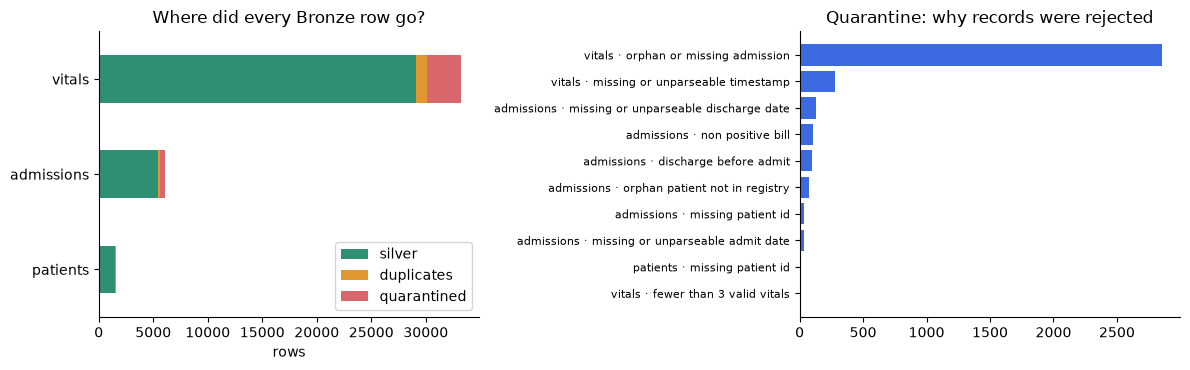

In [13]:
# ───────── Before vs After: the cleaning, visible ─────────
print("▶ GENDER — bronze (inconsistent) vs silver (standardized)")
p0.groupBy("gender").count().orderBy(F.desc("count")).show(15)
silver_patients.groupBy("gender").count().orderBy(F.desc("count")).show()

print("▶ TOTAL BILL — raw text vs cleaned numeric")
(a0.select("admission_id", F.col("total_bill").alias("bill_raw")).dropDuplicates(["admission_id"])
   .join(silver_admissions.select("admission_id", "total_bill", "bill_imputed"), "admission_id")
   .filter(F.col("bill_raw").rlike(r"[^0-9]") | F.col("bill_raw").isNull()).orderBy("admission_id").show(8))

print("▶ TEMPERATURE — Fahrenheit readings converted to °C")
(v0.filter(F.col("temp_unit") == "F").select("reading_id", F.col("temperature").alias("temp_raw"), "temp_unit").dropDuplicates(["reading_id"])
   .join(silver_vitals.select("reading_id", "temperature_c"), "reading_id").orderBy("reading_id").show(5))

fig, axes = plt.subplots(1, 2, figsize=(12, 3.8))
recon_df.set_index("entity")[["silver", "duplicates", "quarantined"]].plot.barh(stacked=True, ax=axes[0], color=["#2F8F73", "#E0972E", "#D9666B"])
axes[0].set_title("Where did every Bronze row go?"); axes[0].set_xlabel("rows"); axes[0].set_ylabel("")
axes[0].spines[["top", "right"]].set_visible(False)
q_reasons = (spark.read.parquet(str(QUARANTINE / "rejected_records")).groupBy("entity", "reject_reason").count().toPandas()
             .sort_values("count"))
axes[1].barh(q_reasons["entity"] + " · " + q_reasons["reject_reason"].str.replace("_", " "), q_reasons["count"], color="#3E6AE1")
axes[1].set_title("Quarantine: why records were rejected"); axes[1].tick_params(axis="y", labelsize=8)
axes[1].spines[["top", "right"]].set_visible(False)
plt.tight_layout(); plt.show()

## 5. PySpark processing
Using the Silver tables: filtering, joins (including a broadcast join), transformations, aggregations and pivot, Spark SQL, and window functions (`row_number`, `lag`, `lead`, running totals, rolling averages, `dense_rank`). The key derived column is `readmitted_within_30d`, computed with `lead()` over each patient's admission history.

In [14]:
# ───────── 5.1  Load Silver + FILTERING ─────────
pat = spark.read.parquet(str(SILVER / "patients"))
adm = spark.read.parquet(str(SILVER / "admissions"))
vit = spark.read.parquet(str(SILVER / "vitals"))
print(f"Loaded Silver:  patients={pat.count():,}  admissions={adm.count():,}  vitals={vit.count():,}\n")

critical_emergencies = adm.filter((F.col("admission_type") == "Emergency") & (F.col("severity") >= 4))
seniors_chronic      = pat.filter((F.col("age") >= 60) & (F.col("has_diabetes") | F.col("has_hypertension")))
critical_vitals      = vit.filter((F.col("spo2") < 90) | (F.col("temperature_c") >= 39.5) | (F.col("heart_rate") > 130))

print(f"Emergency admissions with severity ≥ 4 : {critical_emergencies.count():,}")
print(f"Senior (60+) patients with chronic disease: {seniors_chronic.count():,}")
print(f"Readings with critical vitals (SpO₂<90, temp≥39.5°C or HR>130): {critical_vitals.count():,}")
critical_emergencies.select("admission_id", "department", "primary_diagnosis", "severity", "length_of_stay_days", "total_bill").show(5)

Loaded Silver:  patients=1,500  admissions=5,464  vitals=29,132



Emergency admissions with severity ≥ 4 : 677


Senior (60+) patients with chronic disease: 183


Readings with critical vitals (SpO₂<90, temp≥39.5°C or HR>130): 100
+------------+----------+--------------------+--------+-------------------+----------+
|admission_id|department|   primary_diagnosis|severity|length_of_stay_days|total_bill|
+------------+----------+--------------------+--------+-------------------+----------+
|     A000702|Nephrology|Chronic Kidney Di...|       5|                 11|  171807.0|
|     A001037|Nephrology|       Kidney Stones|       5|                  7|  178427.0|
|     A001208|Nephrology|       Kidney Stones|       5|                 11|  354167.0|
|     A001426|Nephrology|       Kidney Stones|       5|                 24|  584610.0|
|     A001490|Nephrology|       Kidney Stones|       5|                  7|  163284.0|
+------------+----------+--------------------+--------+-------------------+----------+
only showing top 5 rows


In [15]:
# ───────── 5.2  TRANSFORMATIONS + JOIN (admissions ⨝ patient dimension) ─────────
age_group = (F.when(F.col("age") < 13, "Child (0-12)").when(F.col("age") < 18, "Teen (13-17)")
              .when(F.col("age") < 40, "Adult (18-39)").when(F.col("age") < 60, "Middle-aged (40-59)").otherwise("Senior (60+)"))
age_sort  = (F.when(F.col("age") < 13, 1).when(F.col("age") < 18, 2).when(F.col("age") < 40, 3).when(F.col("age") < 60, 4).otherwise(5))

pat_dim = pat.select("patient_id", "gender", "age", age_group.alias("age_group"), age_sort.alias("age_group_sort"),
                     "city", "blood_group", "insurance_type", "has_diabetes", "has_hypertension")

enriched = (adm.join(F.broadcast(pat_dim), "patient_id", "inner")                  # small dimension table -> broadcast join
    .withColumn("admit_month", F.date_trunc("month", "admit_ts").cast("date"))
    .withColumn("admit_weekday", F.date_format("admit_ts", "E"))
    .withColumn("cost_per_day", F.round(F.col("total_bill") / F.col("length_of_stay_days"), 0))
    .withColumn("los_bucket", F.when(F.col("length_of_stay_days") <= 2, "1. Short (1-2d)").when(F.col("length_of_stay_days") <= 5, "2. Medium (3-5d)")
                               .when(F.col("length_of_stay_days") <= 9, "3. Long (6-9d)").otherwise("4. Extended (10d+)"))
    .withColumn("is_chronic", (F.col("has_diabetes") | F.col("has_hypertension")).cast("int")))

print("Enriched admissions:", enriched.count(), "rows ×", len(enriched.columns), "columns (admission ⨝ patient)")
enriched.select("admission_id", "department", "age", "age_group", "los_bucket", "cost_per_day", "admit_month", "is_chronic").show(6)

Enriched admissions: 5464 rows × 30 columns (admission ⨝ patient)


+------------+-------------+---+-------------------+----------------+------------+-----------+----------+
|admission_id|   department|age|          age_group|      los_bucket|cost_per_day|admit_month|is_chronic|
+------------+-------------+---+-------------------+----------------+------------+-----------+----------+
|     A000059|Endocrinology| 45|Middle-aged (40-59)|  3. Long (6-9d)|      6247.0| 2024-10-01|         0|
|     A000122|Endocrinology| 62|       Senior (60+)|2. Medium (3-5d)|     10468.0| 2024-10-01|         0|
|     A000132|Endocrinology| 30|      Adult (18-39)|2. Medium (3-5d)|      9203.0| 2024-10-01|         0|
|     A000197|Endocrinology| 30|      Adult (18-39)|2. Medium (3-5d)|      9842.0| 2024-10-01|         0|
|     A000233|Endocrinology| 41|Middle-aged (40-59)|2. Medium (3-5d)|     12126.0| 2024-11-01|         0|
|     A000280|Endocrinology| 40|Middle-aged (40-59)|  3. Long (6-9d)|      9618.0| 2024-11-01|         0|
+------------+-------------+---+--------------

In [16]:
# ───────── 5.3  WINDOW FUNCTIONS — readmission detection per patient ─────────
w_pat = Window.partitionBy("patient_id").orderBy("admit_ts")

adm_w = (enriched
    .withColumn("admission_seq",       F.row_number().over(w_pat))                               # 1st, 2nd, 3rd ... visit
    .withColumn("prev_discharge_ts",   F.lag("discharge_ts").over(w_pat))                        # previous stay's discharge
    .withColumn("days_since_last_discharge", F.datediff("admit_ts", "prev_discharge_ts"))
    .withColumn("is_readmission_30d",  F.when(F.col("days_since_last_discharge").between(0, 30), 1).otherwise(0))
    .withColumn("next_admit_ts",       F.lead("admit_ts").over(w_pat))                           # next stay's admission
    .withColumn("readmitted_within_30d", F.when(F.datediff("next_admit_ts", "discharge_ts").between(0, 30), 1).otherwise(0))  # ← ML label
    .withColumn("cumulative_bill",     F.sum("total_bill").over(w_pat.rowsBetween(Window.unboundedPreceding, Window.currentRow)))
    .withColumn("visits_so_far",       F.count("*").over(w_pat.rowsBetween(Window.unboundedPreceding, Window.currentRow))))

print("One patient's admission history, as seen through the window functions:")
sample_pid = (adm_w.filter(F.col("readmitted_within_30d") == 1).select("patient_id").first()[0])
(adm_w.filter(F.col("patient_id") == sample_pid)
      .select("patient_id", "admission_seq", "admit_ts", "discharge_ts", "days_since_last_discharge",
              "is_readmission_30d", "readmitted_within_30d", "cumulative_bill").orderBy("admission_seq").show(truncate=False))

n_all = adm_w.count()
n_pos = adm_w.filter("readmitted_within_30d = 1").count()
print(f"30-day readmission label: {n_pos:,} of {n_all:,} admissions ({100 * n_pos / n_all:.1f}%) are followed by a re-admission within 30 days")

One patient's admission history, as seen through the window functions:


+----------+-------------+-------------------+-------------------+-------------------------+------------------+---------------------+---------------+
|patient_id|admission_seq|admit_ts           |discharge_ts       |days_since_last_discharge|is_readmission_30d|readmitted_within_30d|cumulative_bill|
+----------+-------------+-------------------+-------------------+-------------------------+------------------+---------------------+---------------+
|P00001    |1            |2025-10-04 07:27:00|2025-10-14 08:27:00|NULL                     |0                 |0                    |144321.0       |
|P00001    |2            |2025-12-26 00:55:00|2025-12-29 02:55:00|73                       |0                 |1                    |182196.0       |
|P00001    |3            |2026-01-01 10:21:00|2026-01-06 14:21:00|3                        |1                 |0                    |223924.0       |
|P00001    |4            |2026-06-23 02:22:00|2026-06-27 06:22:00|168                      |0       

30-day readmission label: 1,384 of 5,464 admissions (25.3%) are followed by a re-admission within 30 days


In [17]:
# ───────── 5.4  Vitals processing: clinical alert flags, rolling window, per-admission aggregation ─────────
flags = (vit
    .withColumn("tachycardia",   (F.col("heart_rate") > 100).cast("int"))
    .withColumn("hypoxemia",     (F.col("spo2") < 92).cast("int"))
    .withColumn("hypertension",  ((F.col("systolic_bp") >= 140) | (F.col("diastolic_bp") >= 90)).cast("int"))
    .withColumn("fever",         (F.col("temperature_c") >= 38.0).cast("int"))
    .withColumn("hyperglycemia", (F.col("blood_glucose") >= 180).cast("int"))
    .withColumn("alert_count",   F.col("tachycardia") + F.col("hypoxemia") + F.col("hypertension") + F.col("fever") + F.col("hyperglycemia")))

w_v = Window.partitionBy("admission_id").orderBy("recorded_ts")
flags = (flags.withColumn("reading_no", F.row_number().over(w_v))
              .withColumn("hr_rolling_avg_3", F.round(F.avg("heart_rate").over(w_v.rowsBetween(-2, 0)), 1)))   # trailing 3-reading average

vitals_by_admission = (flags.groupBy("admission_id").agg(
    F.count("*").alias("n_readings"),
    F.round(F.avg("heart_rate"), 1).alias("avg_hr"), F.max("heart_rate").alias("max_hr"),
    F.min("spo2").alias("min_spo2"), F.round(F.max("temperature_c"), 1).alias("max_temp_c"),
    F.max("systolic_bp").alias("max_systolic_bp"), F.round(F.avg("blood_glucose"), 0).alias("avg_glucose"),
    F.sum("alert_count").alias("total_alerts"), F.round(F.avg("alert_count"), 2).alias("alerts_per_reading"),
    (F.max_by("heart_rate", "recorded_ts") - F.min_by("heart_rate", "recorded_ts")).alias("hr_change_first_to_last")))

print("Share of readings raising each clinical alert:")
flags.agg(*[F.round(100 * F.avg(c), 1).alias(c + "_%") for c in ["tachycardia", "hypoxemia", "hypertension", "fever", "hyperglycemia"]]).show()
vitals_by_admission.orderBy(F.desc("total_alerts")).show(5)

Share of readings raising each clinical alert:


+-------------+-----------+--------------+-------+---------------+
|tachycardia_%|hypoxemia_%|hypertension_%|fever_%|hyperglycemia_%|
+-------------+-----------+--------------+-------+---------------+
|          3.5|        3.6|          20.2|    3.4|            5.1|
+-------------+-----------+--------------+-------+---------------+



+------------+----------+------+------+--------+----------+---------------+-----------+------------+------------------+-----------------------+
|admission_id|n_readings|avg_hr|max_hr|min_spo2|max_temp_c|max_systolic_bp|avg_glucose|total_alerts|alerts_per_reading|hr_change_first_to_last|
+------------+----------+------+------+--------+----------+---------------+-----------+------------+------------------+-----------------------+
|     A001241|         6|  94.2|   111|      90|      38.4|            147|      190.0|          14|              2.33|                    -30|
|     A004616|         6|  91.8|   107|      91|      38.3|            143|      172.0|          14|              2.33|                    -28|
|     A003137|         6|  89.3|   103|      90|      38.3|            150|      178.0|          14|              2.33|                    -25|
|     A000924|         6|  90.8|   102|      91|      38.0|            143|      191.0|          14|              2.33|                 

In [18]:
# ───────── 5.5  JOINS + AGGREGATIONS → analysis-ready datasets ─────────
# (a) admission-level feature table: admissions (with window features) LEFT JOIN vitals aggregates
admission_features = adm_w.join(vitals_by_admission, "admission_id", "left").cache()
print("admission_features:", admission_features.count(), "rows ×", len(admission_features.columns), "columns")

# (b) department KPIs (groupBy + agg) with a ranking window
dept_kpis = (admission_features.groupBy("department").agg(
        F.count("*").alias("admissions"), F.countDistinct("patient_id").alias("unique_patients"),
        F.round(F.avg("length_of_stay_days"), 2).alias("avg_los_days"), F.round(F.avg("total_bill"), 0).alias("avg_bill_inr"),
        F.round(100 * F.avg((F.col("outcome") == "Deceased").cast("int")), 2).alias("mortality_pct"),
        F.round(100 * F.avg("readmitted_within_30d"), 2).alias("readmission_30d_pct"),
        F.round(F.avg("total_alerts"), 2).alias("avg_vital_alerts"))
    .withColumn("cost_rank", F.dense_rank().over(Window.orderBy(F.desc("avg_bill_inr"))))
    .orderBy(F.desc("admissions")))
print("\n▶ Department KPIs"); dept_kpis.show(truncate=False)

# (c) monthly trend with a rolling 3-month average and month-over-month change (window over time)
w_m = Window.orderBy("admit_month")
monthly_trend = (admission_features.groupBy("admit_month").agg(
        F.count("*").alias("admissions"), F.round(F.sum("total_bill") / 1e5, 2).alias("billing_lakh_inr"))
    .withColumn("rolling_3m_avg", F.round(F.avg("admissions").over(w_m.rowsBetween(-2, 0)), 1))
    .withColumn("mom_change_pct", F.round(100 * (F.col("admissions") - F.lag("admissions").over(w_m)) / F.lag("admissions").over(w_m), 1))
    .orderBy("admit_month"))
print("▶ Monthly trend (first 6 months)"); monthly_trend.show(6)

# (d) top-3 diagnoses per department: row_number + share-of-department (windows)
w_d = Window.partitionBy("department")
top_dx = (admission_features.filter(F.col("primary_diagnosis") != "Unspecified")
    .groupBy("department", "primary_diagnosis").agg(F.count("*").alias("cases"), F.round(F.avg("length_of_stay_days"), 1).alias("avg_los"))
    .withColumn("share_of_dept_pct", F.round(100 * F.col("cases") / F.sum("cases").over(w_d), 1))
    .withColumn("rank_in_dept", F.row_number().over(w_d.orderBy(F.desc("cases"))))
    .filter("rank_in_dept <= 3").orderBy("department", "rank_in_dept"))
print("▶ Top-3 diagnoses per department"); top_dx.show(21, truncate=False)

# (e) pivot: age group × admission type
print("▶ Admissions by age group × admission type (pivot)")
(admission_features.groupBy("age_group_sort", "age_group").pivot("admission_type", ["Emergency", "Urgent", "Elective"]).count()
    .orderBy("age_group_sort").drop("age_group_sort").show(truncate=False))

# (f) patient-level summary (join with patient dimension)
patient_summary = (admission_features.groupBy("patient_id").agg(
        F.count("*").alias("total_admissions"), F.round(F.sum("total_bill"), 0).alias("total_bill_inr"),
        F.round(F.avg("length_of_stay_days"), 1).alias("avg_los_days"), F.sum("is_readmission_30d").alias("readmissions_30d"),
        F.sum((F.col("admission_type") == "Emergency").cast("int")).alias("emergency_admissions"), F.max("admit_ts").alias("last_admit_ts"))
    .join(pat_dim, "patient_id", "inner"))
print("patient_summary:", patient_summary.count(), "patients")

admission_features: 5464 rows × 48 columns

▶ Department KPIs


+----------------+----------+---------------+------------+------------+-------------+-------------------+----------------+---------+
|department      |admissions|unique_patients|avg_los_days|avg_bill_inr|mortality_pct|readmission_30d_pct|avg_vital_alerts|cost_rank|
+----------------+----------+---------------+------------+------------+-------------+-------------------+----------------+---------+
|General Medicine|1427      |808            |4.64        |34218.0     |1.4          |26.84              |1.66            |7        |
|Cardiology      |874       |584            |7.52        |133647.0    |0.8          |23.68              |2.05            |3        |
|Orthopedics     |752       |533            |8.66        |174296.0    |0.8          |25.8               |1.93            |1        |
|Pulmonology     |737       |505            |7.37        |103307.0    |1.76         |24.97              |1.97            |5        |
|Endocrinology   |621       |453            |6.16        |70670.0    

+-----------+----------+----------------+--------------+--------------+
|admit_month|admissions|billing_lakh_inr|rolling_3m_avg|mom_change_pct|
+-----------+----------+----------------+--------------+--------------+
| 2024-10-01|       198|          202.07|         198.0|          NULL|
| 2024-11-01|       241|          232.71|         219.5|          21.7|
| 2024-12-01|       256|          250.85|         231.7|           6.2|
| 2025-01-01|       251|          252.78|         249.3|          -2.0|
| 2025-02-01|       206|          224.81|         237.7|         -17.9|
| 2025-03-01|       252|           289.4|         236.3|          22.3|
+-----------+----------+----------------+--------------+--------------+
only showing top 6 rows
▶ Top-3 diagnoses per department


+----------------+----------------------+-----+-------+-----------------+------------+
|department      |primary_diagnosis     |cases|avg_los|share_of_dept_pct|rank_in_dept|
+----------------+----------------------+-----+-------+-----------------+------------+
|Cardiology      |Arrhythmia            |239  |7.2    |27.6             |1           |
|Cardiology      |Heart Failure         |215  |7.5    |24.9             |2           |
|Cardiology      |Hypertensive Crisis   |207  |7.7    |23.9             |3           |
|Endocrinology   |Thyroid Disorder      |209  |6.4    |34.4             |1           |
|Endocrinology   |Diabetic Ketoacidosis |204  |6.0    |33.6             |2           |
|Endocrinology   |Type 2 Diabetes       |195  |6.1    |32.1             |3           |
|General Medicine|Dengue                |363  |4.6    |26.0             |1           |
|General Medicine|Typhoid               |362  |4.6    |26.0             |2           |
|General Medicine|Gastroenteritis       |34

+-------------------+---------+------+--------+
|age_group          |Emergency|Urgent|Elective|
+-------------------+---------+------+--------+
|Child (0-12)       |27       |7     |23      |
|Teen (13-17)       |39       |15    |29      |
|Adult (18-39)      |824      |275   |515     |
|Middle-aged (40-59)|1094     |346   |632     |
|Senior (60+)       |827      |278   |533     |
+-------------------+---------+------+--------+



patient_summary: 1358 patients


In [19]:
# ───────── 5.6  SPARK SQL ─────────
admission_features.createOrReplaceTempView("admission_features")
pat_dim.createOrReplaceTempView("patients_dim")

print("▶ Q1 — Department performance report (CASE, GROUP BY, ORDER BY)")
spark.sql("""
    SELECT department,
           COUNT(*)                                                         AS admissions,
           ROUND(AVG(length_of_stay_days), 2)                               AS avg_los_days,
           SUM(CASE WHEN admission_type = 'Emergency' THEN 1 ELSE 0 END)    AS emergency_cases,
           ROUND(100.0 * SUM(CASE WHEN admission_type = 'Emergency' THEN 1 ELSE 0 END) / COUNT(*), 1) AS emergency_pct,
           ROUND(100.0 * AVG(readmitted_within_30d), 2)                     AS readmission_pct
    FROM admission_features
    GROUP BY department
    ORDER BY admissions DESC
""").show(truncate=False)

print("▶ Q2 — High-risk chronic patients: ≥3 admissions, ranked by readmissions then spend (CTE + JOIN + RANK window)")
spark.sql("""
    WITH patient_stats AS (
        SELECT patient_id, COUNT(*) AS admissions, SUM(is_readmission_30d) AS readmissions, SUM(total_bill) AS total_bill
        FROM admission_features
        GROUP BY patient_id
    )
    SELECT s.patient_id, p.age, p.gender, p.city, s.admissions, s.readmissions, ROUND(s.total_bill) AS total_bill_inr,
           RANK() OVER (ORDER BY s.readmissions DESC, s.total_bill DESC) AS risk_rank
    FROM patient_stats s
    JOIN patients_dim p ON s.patient_id = p.patient_id
    WHERE (p.has_diabetes OR p.has_hypertension) AND s.admissions >= 3
    ORDER BY risk_rank
    LIMIT 10
""").show(truncate=False)

print("▶ Q3 — Longest-stay diagnosis in each department (RANK() OVER PARTITION BY, in SQL)")
spark.sql("""
    SELECT department, primary_diagnosis, cases, avg_los_days FROM (
        SELECT department, primary_diagnosis, COUNT(*) AS cases,
               ROUND(AVG(length_of_stay_days), 1) AS avg_los_days,
               RANK() OVER (PARTITION BY department ORDER BY AVG(length_of_stay_days) DESC) AS los_rank
        FROM admission_features
        WHERE primary_diagnosis <> 'Unspecified'
        GROUP BY department, primary_diagnosis
    ) t
    WHERE los_rank = 1
    ORDER BY avg_los_days DESC
""").show(truncate=False)

▶ Q1 — Department performance report (CASE, GROUP BY, ORDER BY)


+----------------+----------+------------+---------------+-------------+---------------+
|department      |admissions|avg_los_days|emergency_cases|emergency_pct|readmission_pct|
+----------------+----------+------------+---------------+-------------+---------------+
|General Medicine|1427      |4.64        |768            |53.8         |26.84          |
|Cardiology      |874       |7.52        |439            |50.2         |23.68          |
|Orthopedics     |752       |8.66        |369            |49.1         |25.8           |
|Pulmonology     |737       |7.37        |395            |53.6         |24.97          |
|Endocrinology   |621       |6.16        |315            |50.7         |26.41          |
|Neurology       |593       |8.62        |300            |50.6         |24.28          |
|Nephrology      |460       |7.43        |225            |48.9         |23.48          |
+----------------+----------+------------+---------------+-------------+---------------+

▶ Q2 — High-risk chr

+----------+---+------+----------+----------+------------+--------------+---------+
|patient_id|age|gender|city      |admissions|readmissions|total_bill_inr|risk_rank|
+----------+---+------+----------+----------+------------+--------------+---------+
|P00803    |65 |Female|Delhi     |19        |11          |2284902.0     |1        |
|P00955    |50 |Male  |Chennai   |14        |11          |1342050.0     |2        |
|P00377    |91 |Male  |Lucknow   |17        |7           |1625597.0     |3        |
|P01370    |69 |Female|Delhi     |15        |7           |1584351.0     |4        |
|P00040    |37 |Male  |Chandigarh|11        |7           |1391086.0     |5        |
|P00640    |68 |Male  |Bengaluru |14        |6           |1897553.0     |6        |
|P00128    |53 |Male  |Chandigarh|12        |6           |1411673.0     |7        |
|P01377    |76 |Female|Bengaluru |11        |6           |1241355.0     |8        |
|P00152    |63 |Female|Mumbai    |13        |6           |1232168.0     |9  

+----------------+----------------------+-----+------------+
|department      |primary_diagnosis     |cases|avg_los_days|
+----------------+----------------------+-----+------------+
|Neurology       |Stroke                |202  |8.8         |
|Orthopedics     |Joint Replacement     |231  |8.8         |
|Cardiology      |Myocardial Infarction |204  |7.8         |
|Nephrology      |Chronic Kidney Disease|216  |7.6         |
|Pulmonology     |COPD Exacerbation     |253  |7.4         |
|Endocrinology   |Thyroid Disorder      |209  |6.4         |
|General Medicine|Viral Fever           |325  |4.7         |
+----------------+----------------------+-----+------------+



Processed layer written (Parquet):


  processed/admission_features    5,464 rows
  processed/dept_kpis                 7 rows


  processed/monthly_trend            24 rows
  processed/top_diagnoses            20 rows


  processed/patient_summary       1,358 rows


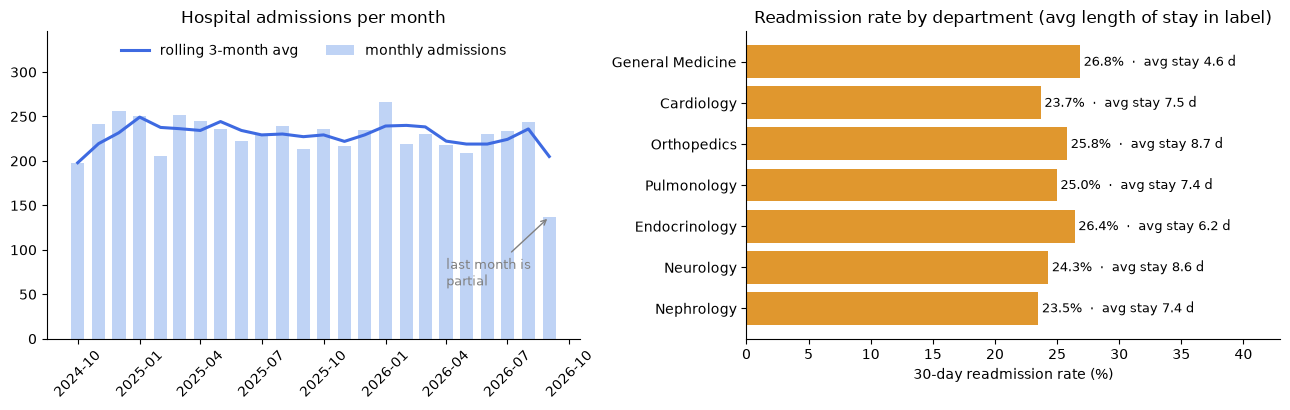

In [20]:
# ───────── 5.7  Persist processed datasets + dashboard-style charts ─────────
outputs = {"admission_features": admission_features, "dept_kpis": dept_kpis, "monthly_trend": monthly_trend,
           "top_diagnoses": top_dx, "patient_summary": patient_summary}
for name, df in outputs.items():
    df.write.mode("overwrite").parquet(str(PROCESSED / name))
print("Processed layer written (Parquet):")
for name in outputs:
    print(f"  processed/{name:<20} {spark.read.parquet(str(PROCESSED / name)).count():>6,} rows")

mt = monthly_trend.toPandas(); mt["admit_month"] = pd.to_datetime(mt["admit_month"])
dk = dept_kpis.toPandas().sort_values("admissions")

fig, axes = plt.subplots(1, 2, figsize=(13, 4.2))
axes[0].bar(mt["admit_month"], mt["admissions"], width=20, color="#BFD3F5", label="monthly admissions")
axes[0].plot(mt["admit_month"], mt["rolling_3m_avg"], color="#3E6AE1", linewidth=2.2, label="rolling 3-month avg")
axes[0].set_ylim(0, mt["admissions"].max() * 1.3); axes[0].set_title("Hospital admissions per month"); axes[0].legend(frameon=False, loc="upper center", ncol=2); axes[0].tick_params(axis="x", rotation=45)
axes[0].spines[["top", "right"]].set_visible(False)

bars = axes[1].barh(dk["department"], dk["readmission_30d_pct"], color="#E0972E")
for bar, pct, los in zip(bars, dk["readmission_30d_pct"], dk["avg_los_days"]):
    axes[1].text(bar.get_width() + 0.3, bar.get_y() + bar.get_height() / 2, f"{pct:.1f}%  ·  avg stay {los:.1f} d", va="center", fontsize=9)
axes[1].set_xlim(0, dk["readmission_30d_pct"].max() * 1.6)
axes[1].set_xlabel("30-day readmission rate (%)")
axes[1].set_title("Readmission rate by department (avg length of stay in label)"); axes[1].spines[["top", "right"]].set_visible(False)
axes[0].annotate("last month is\npartial", xy=(mt["admit_month"].iloc[-1], mt["admissions"].iloc[-1]),
                 xytext=(mt["admit_month"].iloc[-6], 60), arrowprops=dict(arrowstyle="->", color="grey"), fontsize=9, color="grey")
plt.tight_layout(); plt.show()

## Wrap-up

In [21]:
summary = pd.DataFrame([
    ("Sources",          "CSV + database + REST API",           f"{sum(SOURCE_ROWS.values()):,} rows (3 sources)"),
    ("Bronze",           "raw + lineage, Parquet",               f"{sum(SOURCE_ROWS.values()):,} rows — 100% retained"),
    ("Silver",           "typed, standardized, validated",       f"{n_silver_p + n_silver_a + n_silver_v:,} rows kept"),
    ("Quarantine",       "rejected + reason + raw record",       f"{n_q_p + n_q_a + n_q_v:,} rows"),
    ("Duplicates",       "removed in Silver",                    f"{p_dups + a_dups + v_dups:,} rows"),
    ("Processed (PySpark)", "features, KPIs, trends, summaries",  f"{admission_features.count():,} admission feature rows"),
], columns=["layer", "what it holds", "volume"])
print(summary.to_string(index=False))

print("\nTables on disk:")
for p_ in sorted(BASE.glob("*/*")):
    print("  ", p_)

print(f"\nReady for the next phase: `admission_features` carries the target label `readmitted_within_30d` "
      f"({100 * n_pos / n_all:.1f}% positive) plus patient, admission and vitals features for the MLlib model.")

              layer                     what it holds                       volume
            Sources         CSV + database + REST API      40,878 rows (3 sources)
             Bronze            raw + lineage, Parquet  40,878 rows — 100% retained
             Silver    typed, standardized, validated             36,096 rows kept
         Quarantine    rejected + reason + raw record                   3,607 rows
         Duplicates                 removed in Silver                   1,175 rows
Processed (PySpark) features, KPIs, trends, summaries 5,464 admission feature rows

Tables on disk:
   healthcare_pipeline/bronze/admissions
   healthcare_pipeline/bronze/patients
   healthcare_pipeline/bronze/vitals
   healthcare_pipeline/processed/admission_features
   healthcare_pipeline/processed/dept_kpis
   healthcare_pipeline/processed/monthly_trend
   healthcare_pipeline/processed/patient_summary
   healthcare_pipeline/processed/top_diagnoses
   healthcare_pipeline/quarantine/rejected_reco

## Conclusion
The pipeline takes three messy hospital sources to clean, auditable Silver tables and analysis-ready outputs (`processed/`), with every row accounted for and rejected records kept in quarantine. `admission_features` already contains the 30-day readmission label and patient, admission and vitals features, so it can be used directly for model building in the next phase.

**To re-run:** Python 3.9+, Java 17 or 21 (needed by Spark 4), `pip install pyspark pandas numpy matplotlib`, then Run All (about 2 minutes).